#Travel Money Helper
A finance assistant that helps travellers plan how much money they should prepare for a trip. It calculates user personalised travel costs and compares the total cost with the user's available budget.

This program calculates the total costs by breaking it into visa, flights, accommodation, meals, travel insurance, transport fee, and emergency money. It uses a CSV file containing example travel costs for several different destinations. However, users can also enter their own costs and destination to personalise their travel budget.

The project also uses the Gemini API to provide budgeting suggestions based on the user's travel costs and available budget.

**Understanding the problem**

I want to create a Travel Money Helper to help people plan their travel budget.

My program will help users estimate their travel costs such as visa, flight, accommodation, meals, travel insurance, transport fees, and emergency money based on their destination and the number of days they are travelling. It will use the estimated costs from a CSV file, but users can also enter their own costs. If their destination is not in the CSV file, or they want to use their own cost, they can enter their travel costs themselves.

This program will calculate the total estimated cost and compare it with the user's available budget. Additionally, it will also use Gemini AI to provide budgeting suggestions to help users plan their money

**Identifying the inputs and outputs**

Inputs:
1. Destination
2. Number of days
3. Budget for the trip
4. Use CSV estimated costs or their own cost, if destination not found in CSV file, users needs to enter their own costs

Outputs:
1. the selected destination
2. the number of travel days
3. the total estimated travel cost
4. the user's available budget
5. the remaining money or budget shortfall
6. budgeting suggestions from Gemini







**An example by hand**

Imagine a user plan to travel to New York for a 3 days trip. 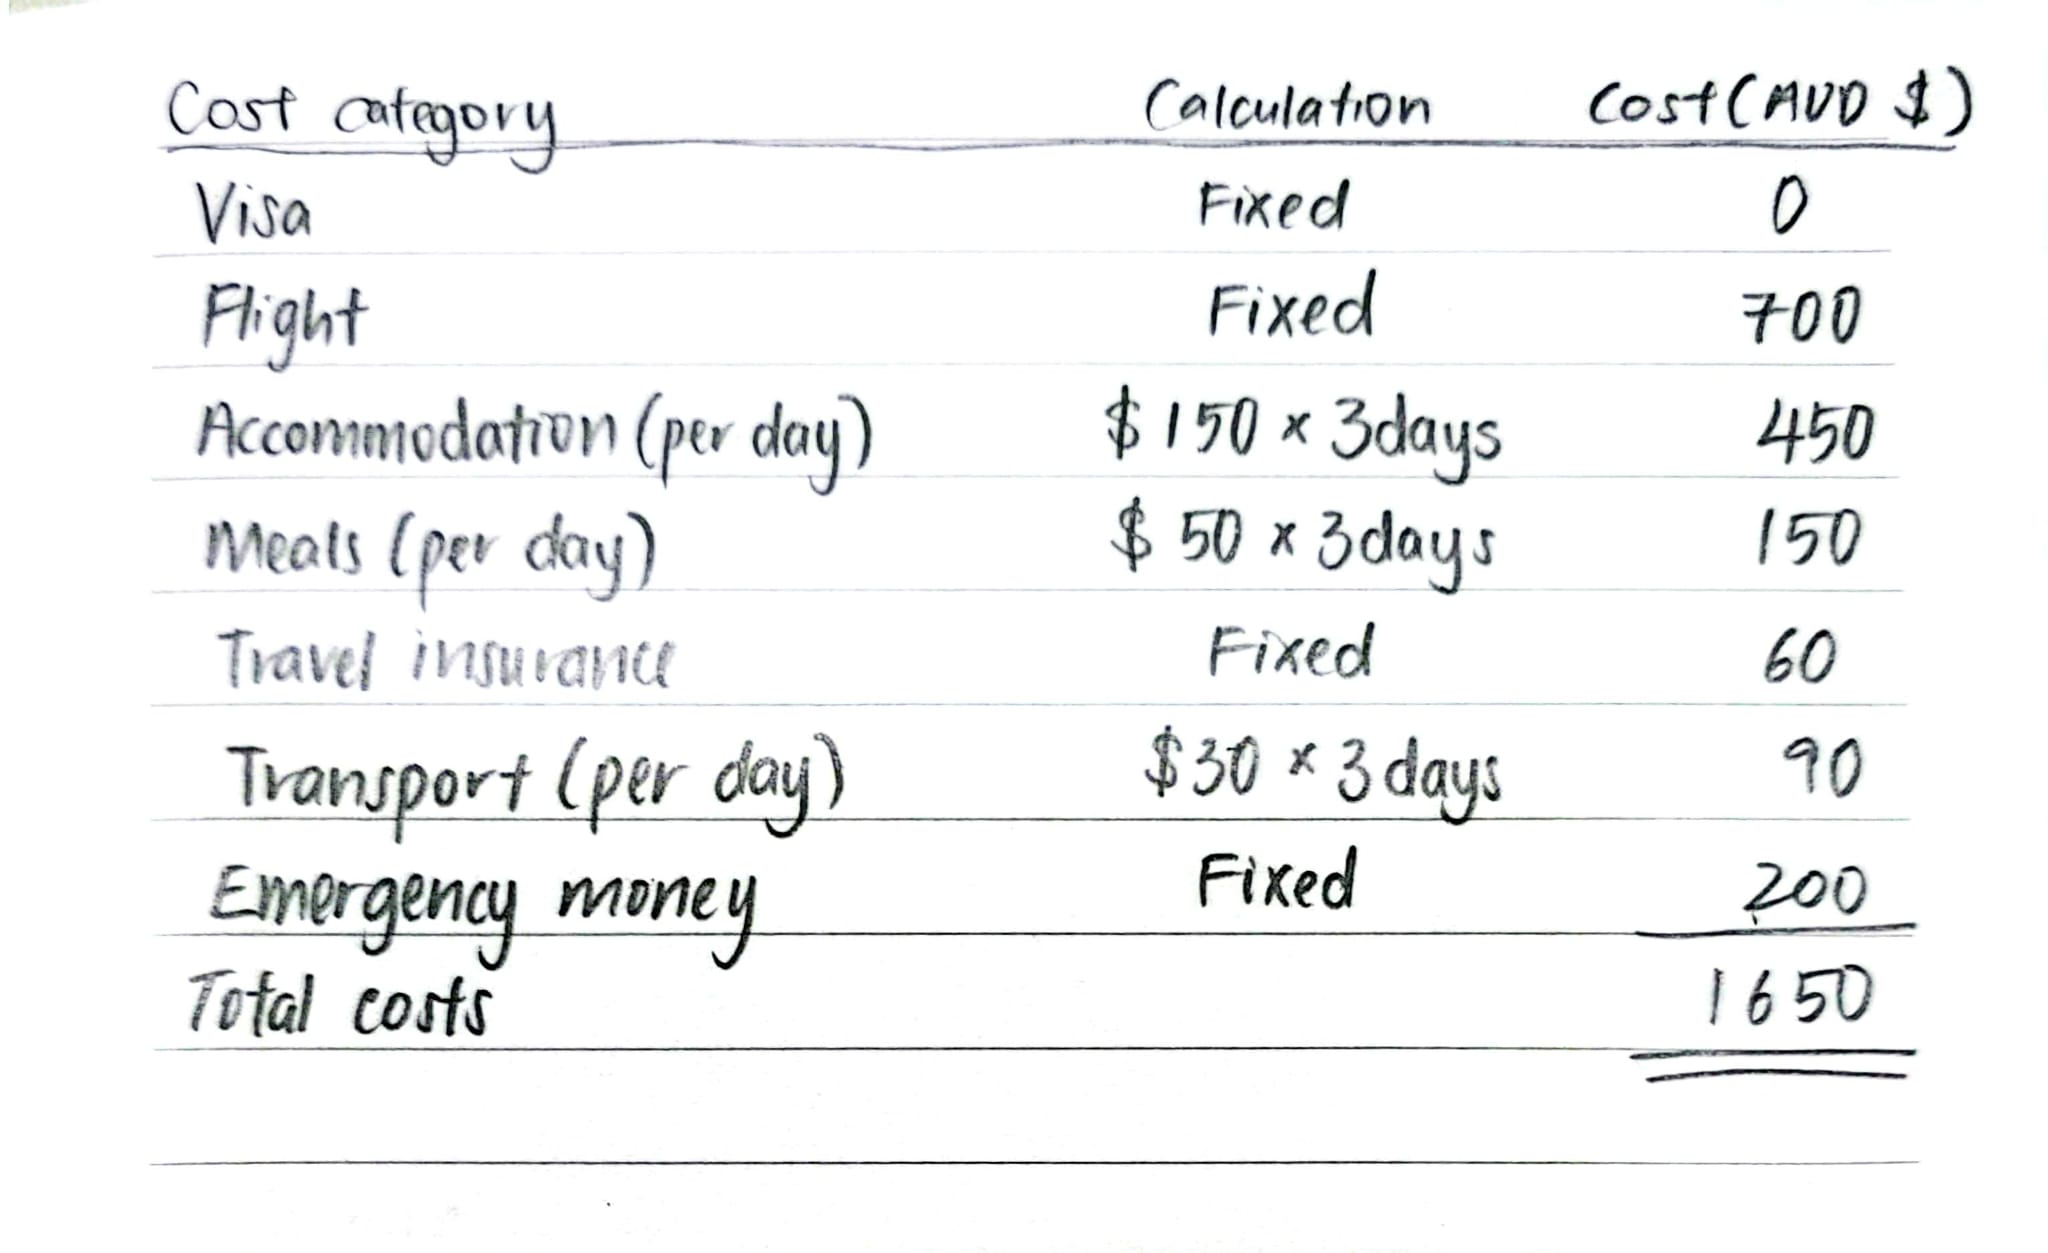

User available budget is AUD $3000

Money remaining = 3000 - 1650 = 1350

This help user estimates their total cost for the trip and if they have remaining or insufficient budget. The daily costs such as accommodation, meals, and transport costs are multiply by the number of days.

**Pseudocode**

START

Reads the estimated travel costs from the Travel Costs.csv file

Ask the user to enter a destination

Ask the user to enter the number of travel days

Ask the user to enter their available budget

Check whether the destination is in the CSV file

IF the destination is found:

    Get the estimated costs from the CSV file, or the user enter their own costs

ELSE:

    Ask the user to enter all their travel costs

Calculate the total travel cost

Compare the total cost with the available budget

IF the budget is enough:

    Display the money remaining

ELSE:

    Display the budget shortfall

Ask Gemini AI for budgeting suggestions

Display the final results

END

**Convert the Pseudocode into Python**

After writing the steps, I created a Travel Costs.csv file and uploaded it to Colab, then used pandas to read the estimated costs from the CSV file. Variables will be used to store the user's inputs, and dictionaries is used to organise the cost categories and their values.

I used if and else statements to check whether the destination is available in the CSV file and whether the user wants to use the estimated costs or their own costs. I also created a function to calculate the total travel cost and check whether the user's budget is enough.

After the budget calculation was working, Gemini AI will be used to provide budgeting suggestions. Lastly, I used Gradio to create an interface where users can enter their travel details and view the results.

###Travel Costs: Estimated costs


My plan, in plain words:
1. Fist, I will load the Travel Costs.csv file into a DataFrame(df).
2. Second, clean the Visa_Cost, Flight_Cost, Accommodation_Cost, Meals_Cost, Travel_Insurance_Cost,
Transport_Cost, Emergency_Money column by removing the dollar signs and commas, then converted the text into a number.

In [3]:
# importing the CSV file
import pandas as pd
df = pd.read_csv('Travel Costs.csv') #reads the Travel Costs CSV file
print(df.head()) #print the first five rows of the CSV data

   Destination Currency Visa_Cost Flight_Cost Accommodation_Cost Meals_Cost  \
0        Japan      AUD     $0.00     $900.00            $180.00     $60.00   
1     Thailand      AUD     $0.00     $500.00             $70.00     $50.00   
2  New Zealand      AUD    $35.00     $600.00            $200.00     $85.00   
3    Singapore      AUD     $0.00     $450.00            $220.00     $80.00   
4     Malaysia      AUD     $0.00     $350.00             $75.00     $35.00   

  Travel_Insurance_Cost Transport_Cost Emergency_Money  
0                $80.00         $30.00         $300.00  
1                $60.00         $30.00         $200.00  
2                $70.00         $70.00         $300.00  
3                $50.00         $30.00         $200.00  
4                $50.00         $20.00         $200.00  


In [4]:
# print the data type of the columns in the CSV file
print(df.dtypes)

Destination              object
Currency                 object
Visa_Cost                object
Flight_Cost              object
Accommodation_Cost       object
Meals_Cost               object
Travel_Insurance_Cost    object
Transport_Cost           object
Emergency_Money          object
dtype: object


In [5]:
# clean Visa_Cost column
df['Visa_Cost'] = df['Visa_Cost'].str.replace('$', '', regex=False) #removes the dollar sign
df['Visa_Cost'] = df['Visa_Cost'].str.replace(',', '', regex=False) #removes the comma
df['Visa_Cost'] = pd.to_numeric(df['Visa_Cost']) #converts text-formatted numbers into a numeric values
# clean Flight_Cost column
df['Flight_Cost'] = df['Flight_Cost'].str.replace('$', '', regex=False)
df['Flight_Cost'] = df['Flight_Cost'].str.replace(',', '', regex=False)
df['Flight_Cost'] = pd.to_numeric(df['Flight_Cost'])
# clean Accommodation_Cost column
df['Accommodation_Cost'] = df['Accommodation_Cost'].str.replace('$', '', regex=False)
df['Accommodation_Cost'] = df['Accommodation_Cost'].str.replace(',', '', regex=False)
df['Accommodation_Cost'] = pd.to_numeric(df['Accommodation_Cost'])
# clean Meals_Cost column
df['Meals_Cost'] = df['Meals_Cost'].str.replace('$', '', regex=False)
df['Meals_Cost'] = df['Meals_Cost'].str.replace(',', '', regex=False)
df['Meals_Cost'] = pd.to_numeric(df['Meals_Cost'])
# clean Travel_Insurance_Cost column
df['Travel_Insurance_Cost'] = df['Travel_Insurance_Cost'].str.replace('$', '', regex=False)
df['Travel_Insurance_Cost'] = df['Travel_Insurance_Cost'].str.replace(',', '', regex=False)
df['Travel_Insurance_Cost'] = pd.to_numeric(df['Travel_Insurance_Cost'])
# clean Transport_Cost column
df['Transport_Cost'] = df['Transport_Cost'].str.replace('$', '', regex=False)
df['Transport_Cost'] = df['Transport_Cost'].str.replace(',', '', regex=False)
df['Transport_Cost'] = pd.to_numeric(df['Transport_Cost'])
# clean Emergency_Money column
df['Emergency_Money'] = df['Emergency_Money'].str.replace('$', '', regex=False)
df['Emergency_Money'] = df['Emergency_Money'].str.replace(',', '', regex=False)
df['Emergency_Money'] = pd.to_numeric(df['Emergency_Money'])

print(df.dtypes)

Destination               object
Currency                  object
Visa_Cost                float64
Flight_Cost              float64
Accommodation_Cost       float64
Meals_Cost               float64
Travel_Insurance_Cost    float64
Transport_Cost           float64
Emergency_Money          float64
dtype: object


###Estimated travel costs

My plan, in plain words:
1. First, I will ask the users to select a destination from the Travel Costs.csv file.
2. Second, I will ask the users how many days they will travel.
3. Third, program will multiplied the cost for accommodation, meals, and transport by the number of days.
4. Fourth, display the estimated costs for the selected destination.

In [6]:
# show all available destinations
print("Available destinations:")

for destination in df['Destination']:   #for loop is used to display each destination from the CSV file,once at a time, and if any update is made to the CSV file it will appear automatically
    print(destination)

# ask user to choose destination
destination = input ('\nEnter your destination:')
#ask user to enter days
days = int(input('Enter days of travel:')) #convert number of days into whole number

# find the selected destination
selected = df[df['Destination'].str.lower() == destination.lower()] #finds the matching row, ignoring uppercase and lowercase differences

if len(selected) > 0:    #check whether the selected destination was found
  print("Destination found")
else:
  print("No reference cost for this destination")

Available destinations:
Japan
Thailand
New Zealand
Singapore
Malaysia
South Korea
London

Enter your destination:japan
Enter days of travel:5
Destination found


In [7]:
# displays the costs if the selected destination is found
if len(selected) > 0:

  # gets the information for the selected destination
  row = selected.iloc[0]  #get the matching destination row from "selected" and stores it in the variable "row"
  print("< Travel cost estimated >")

  # calculate costs based on the number of days
  accommodation_total = row['Accommodation_Cost']*days
  meals_total = row['Meals_Cost']*days
  transport_total = row['Transport_Cost']*days

  # display each estimated cost
  print(f"Visa: AUD ${row['Visa_Cost']:.2f}")
  print(f"Flight: AUD ${row['Flight_Cost']:.2f}")
  print(f"Accommodation: AUD ${accommodation_total:.2f}")
  print(f"Meals: AUD ${meals_total:.2f}")
  print(f"Travel insurance: AUD ${row['Travel_Insurance_Cost']:.2f}")
  print(f"Transport: AUD ${transport_total:.2f}")
  print(f"Emergency money: AUD ${row['Emergency_Money']:.2f}")

  print("\nDestination:", row['Destination']) #gets the selected destination's name from the Travel Costs.csv file
  print("Travel days:", days) #display the number of days entered by the user

  # calculate the estimated total cost
  total_cost = (row['Visa_Cost']
        + row['Flight_Cost']
        + accommodation_total
        + meals_total
        + row['Travel_Insurance_Cost']
        + transport_total
        + row['Emergency_Money']
    )
  print(f"Total estimated cost: AUD ${total_cost:.2f}")

else:
  print("Please enter your own travel costs")


< Travel cost estimated >
Visa: AUD $0.00
Flight: AUD $900.00
Accommodation: AUD $900.00
Meals: AUD $300.00
Travel insurance: AUD $80.00
Transport: AUD $150.00
Emergency money: AUD $300.00

Destination: Japan
Travel days: 5
Total estimated cost: AUD $2630.00


##Personalised costs

My plan, in plain words:

1.   First, if the destination is found, and the user enters N, the program keeps the estimated cost from the CSV. If the user enters Y, they can enter their own cost. If the destination is not found, users get to enter their own destination and costs.
2.   Second, Python then calculates the personalised travel budget using the final chosen costs


In [8]:
# displays the costs if the selected destination is found(check whether the destination exists)
if len(selected) > 0:

  # gets the information for the selected destination
  row = selected.iloc[0]  #get the matching destination row from "selected" and stores it in the variable "row"

  # stores the user's costs
  personalised_costs ={}  #created an empty dictionary that will store the costs chosen by the user

  # list of cost categories and their CSV columns
  cost_columns = {'Visa': 'Visa_Cost',
      'Flight': 'Flight_Cost',
      'Accommodation': 'Accommodation_Cost',
      'Meals': 'Meals_Cost',
      'Travel Insurance': 'Travel_Insurance_Cost',
      'Transport': 'Transport_Cost',
      'Emergency Money': 'Emergency_Money'
   }   #left-hand side of each pair is the name displayed to the user, while right-hand side is the matching column name in the csv file

  # categories that are charged per day
  daily_categories = ['Accommodation', 'Meals', 'Transport']   #a lists that contains three categories that depend on the number of days

  # loop through all the cost categories
  for category, column in cost_columns.items():

      # asks whether the user wants to enter their own cost
      choice = input(
          f"Do you want to enter your own {category} cost? (Y/N): "
      ).strip().upper()

      # check whether the user entered Y or N
      while choice not in ['Y', 'N']:
          print("Please enter Y or N.")
          choice = input(
              f"Do you want to enter your own {category} cost? (Y/N): "
      ).strip().upper()

      # if user entered Y, user entered their own costs
      if choice == 'Y':

         #keep asking until the user enters a number
         while True:
               try:
                 own_cost = float(input(f"Enter your {category} cost: AUD $"))
                 break
               except ValueError:
                 print("Please enter an amount in numbers.")

         # calculate the users own cost
         if category in daily_categories:
            personalised_costs[category] = own_cost * days
         else:
            personalised_costs[category] = own_cost

      # use CSV cost if user entered N
      else:
          if category in daily_categories:
             personalised_costs[category] = row[column] * days
          else:
             personalised_costs[category] = row[column]

# displays if the selected destination is not found
else:
   print("Destination not found in the CSV file.")
   print("Please enter your own travel costs.")

   # store the user's costs
   personalised_costs = {}  #created an empty dictionary that will store all seven costs entered by the user

   # list of cost categories
   cost_categories = ['Visa',
        'Flight',
        'Accommodation',
        'Meals',
        'Travel Insurance',
        'Transport',
        'Emergency Money'
    ]

   # categories that are charged per day
   daily_categories = ['Accommodation', 'Meals', 'Transport']

   # ask the user to enter each cost
   for category in cost_categories:

    # keep asking until the user enters a number
    while True:
      try:
        cost = float(input(f"Enter your {category} cost: AUD $"))
        break
      except ValueError:
        print("Please enter an amount in numbers.")

    # multiply daily costs by the number of days
    if category in daily_categories:
       personalised_costs[category] = cost * days
    else:
       personalised_costs[category] = cost

# calculate the total personalised cost
total_cost = sum(personalised_costs.values())

# display the results
print("\n< Your Personalised Travel Budget >")
print("Destination:", destination)
print("Travel days:", days)

# display each cost
for category, cost in personalised_costs.items():
    print(f"{category}: AUD ${cost:.2f}")

print(f"Total personalised cost: AUD ${total_cost:.2f}")


Do you want to enter your own Visa cost? (Y/N): n
Do you want to enter your own Flight cost? (Y/N): 
Please enter Y or N.
Do you want to enter your own Flight cost? (Y/N): n
Do you want to enter your own Accommodation cost? (Y/N): l
Please enter Y or N.
Do you want to enter your own Accommodation cost? (Y/N): n
Do you want to enter your own Meals cost? (Y/N): y
Enter your Meals cost: AUD $50
Do you want to enter your own Travel Insurance cost? (Y/N): 200
Please enter Y or N.
Do you want to enter your own Travel Insurance cost? (Y/N): n
Do you want to enter your own Transport cost? (Y/N): 20
Please enter Y or N.
Do you want to enter your own Transport cost? (Y/N): n
Do you want to enter your own Emergency Money cost? (Y/N): n

< Your Personalised Travel Budget >
Destination: japan
Travel days: 5
Visa: AUD $0.00
Flight: AUD $900.00
Accommodation: AUD $900.00
Meals: AUD $250.00
Travel Insurance: AUD $80.00
Transport: AUD $150.00
Emergency Money: AUD $300.00
Total personalised cost: AUD $2

##User's available travel budget

My plan, in plain words:
1. First, ask how much is the user
   budget for the trip
2. Second, compare it with total
   personalised cost



In [9]:
# ask the user to enter their available travel budget
available_budget = 0  #gives the variable an initial value so loop can start

# checks whether the budget is positive
while available_budget <= 0:    #keep asking until the user enter an amount greater than zero
  try:
    available_budget = float(input("Enter your available travel budget: AUD $"))

    if available_budget <= 0:
       print("Please enter a positive amount")

  # checks whether the budget entered is a number
  except ValueError:
    print("Please enter an amount in numbers.")
    available_budget = 0    #makes the loop repeat when user enters text

print("Your available budget is AUD $", available_budget)

# compare the available budget with the total personalised travel cost
print("\n< Budget Comparison >")

if available_budget >= total_cost:
   remaining_money = available_budget - total_cost
   print(f"You have sufficient money for your trip")
   print(f"Money remaining: AUD ${remaining_money:.2f}")

else:
  shortfall = total_cost - available_budget
  print("Your budget is insufficient for your trip")
  print(f"Extra money needed: AUD ${shortfall:.2f}")



Enter your available travel budget: AUD $2000
Your available budget is AUD $ 2000.0

< Budget Comparison >
Your budget is insufficient for your trip
Extra money needed: AUD $580.00


##Conversational assistant to give budgeting suggestions

My plan, in plain words:
1. First, set up the API key in colab secrets
2. Second, install and connect to Gemini
3. Third, create the ask_gemini(prompt) function, which accepts a prompt, send it to Gemini and receives the response
4. Fourth, test whether the Gemini works
5. Fifth, connect Gemini to my existing calculated travel budget



In [10]:
# Install and connect to Gemini

# install the Gemini library
!pip install -q -U google-genai

from google.colab import userdata
from google import genai

# gets the Google Gemini API key from colab secrets
API_KEY = userdata.get("GEMINI_API_KEY")

# connects to Gemini
client = genai.Client(api_key = API_KEY)

# specify the Gemini model
MODEL = 'gemini-3.5-flash-lite'

# create the ask_gemini(prompt) function

# defines a function to ask gemini for budgeting suggestion
def ask_gemini(prompt):   #creates a function that receives a question or instruction
    """Send a prompt to Gemini and return its reply."""

    #sets the personality of the travel budgeting assistant
    personality = ("You are a friendly travel budgeting assistant."
    "You include multiple relevant emojis."
    "You give practical and realistic suggestions.")

    try:
      # send the prompt to Gemini
      response = client.models.generate_content(
          model = MODEL,
          contents = personality + "\n\n" + prompt
      )

      # return Gemini response
      return response.text  # gives the response back to the part of your program that called the function

    # handles errors when calling Gemini
    except Exception as e:   # catches an error if the request fails
      return f"Unable to provide suggestions: {e}"  # display a message if an error happens



In [11]:
# A scenario to test whether Gemini works

# create a prompt using the user's travel budget results
prompt = f"""
The user's destination is Japan
The user's total personalised travel cost is AUD $2500
The user's available budget is AUD $2000

Please give me three simple and practical budgeting suggestions.
If my budget is not enough, suggest ways to reduce my costs.
If I have money remaining, suggest how I could manage it.
"""

# sends the prompt to Gemini
suggestions = ask_gemini(prompt)

# return Gemini suggestions
print(suggestions)

Konnichiwa! 🌸 Japan is an absolute dream destination, but I see you're currently looking at a total cost of **AUD $2,500** with an available budget of **AUD $2,000**. 

Don't worry at all! 🙅‍♀️✈️ Being **AUD $500 over budget** is totally manageable with a few smart tweaks. Here are three simple and practical suggestions to help you bridge that gap and have an amazing trip! 

---

### 1. Swap Traditional Hotels for Capsule Hotels, Hostels, or Business Hotels 🏨🛏️
Accommodation can eat up your budget fast. Instead of standard tourist hotels, look into modern Japanese capsule hotels (like *Nine Hours*), clean backpacker hostels, or trusted Japanese business hotel chains like *APA Hotel* or *Toyoko Inn*. 
* **The savings:** This can easily save you $40–$80 per night, which over a week can easily wipe out that $500 difference! Plus, business hotels often include a free breakfast. 🥐☕

### 2. Eat Like a Local at Conbinis and Izakayas 🍱🥢
Dining out at sit-down restaurants for every meal adds up

In [12]:
# Connect Gemini to existing calculated travel budget
def get_budget_suggestions(destination, total_cost, available_budget):

  # creates a prompt using the user travel information
  prompt = f"""
  The user's destination is {destination}
  The user's total personalised travel cost is AUD ${total_cost:.2f}
  The user's available budget is AUD ${available_budget:.2f}

  Please give me three simple and practical budgeting suggestions.
  If my budget is not enough, suggest ways to reduce my costs.
  If I have money remaining, suggest how I could manage it.
  """

  # sends the prompt to Gemini
  suggestions = ask_gemini(prompt)

  # return Gemini suggestions
  return suggestions


In [13]:
# Test whether the Gemini budgeting function

suggestions = get_budget_suggestions(
    destination="Japan",
    total_cost=2500,
    available_budget=2000
)

print(suggestions)


Konnichiwa! 🌸 Japan is an absolute dream destination, but I can definitely help you bridge that small gap so your wallet stays as happy as you will be! 🎌

Right now, your estimated trip comes to **AUD $2,500.00**, but your available budget is **AUD $2,000.00**. That means we just need to find **AUD $500.00** in savings to make this trip completely stress-free! 💸 

Here are three simple and practical ways to trim that $500 off your costs:

### 1. Master the "Konbini" (Convenience Store) Breakfast & Lunch 🍙
Food in Japan is amazing, but costs add up if you eat out for every single meal. 
* **The Swap:** Instead of going to sit-down cafes for breakfast and lunch, head to 7-Eleven, Lawson, or FamilyMart. You can get insanely delicious onigiri (rice balls), egg salad sandwiches, and bento boxes for just a few dollars. 
* **The Savings:** Doing this for a week can easily save you around **AUD $150 – $200**. Plus, Japanese convenience store food is genuinely delicious! 🍱

### 2. Ditch the Shi

##Travel Money Helper interface

My plan, in plain words:
1. First, install Gradio and import the libraries
2. Second, create the processing function
3. Third, create the Gradio interface



In [44]:
# Install and import the libraries

# install the Gradio library
!pip install -q gradio

# import the libraries
import gradio as gr
import pandas as pd

# Create the processing function

# defines a function to receive the user's travel details from Gradio
def get_travel_details(destination, days, available_budget,
    visa_choice, user_visa_cost,
    flight_choice, user_flight_cost,
    accommodation_choice, user_accommodation_cost,
    meals_choice, user_meals_cost,
    insurance_choice, user_travel_insurance_cost,
    transport_choice, user_transport_cost,
    emergency_choice, user_emergency_money):  # creates a function that processes the user's input

    # checks whether the destination is entered
    if not destination or not destination.strip():
        return "Please enter a destination."  # returns an error message if destination is empty or only made up of spaces

    # checks whether the number of days is positive
    if days <= 0:
        return "Please enter a positive number of days"  # returns an error message if days entered is negative

    # checks whether the available budget is positive
    if available_budget <= 0:
        return "Please enter a positive amount"   # returns an error message if the available budget is negative

    # store the user's own costs
    own_costs = {
        "Visa_Cost": user_visa_cost,
        "Flight_Cost": user_flight_cost,
        "Accommodation_Cost": user_accommodation_cost,
        "Meals_Cost": user_meals_cost,
        "Travel_Insurance_Cost": user_travel_insurance_cost,
        "Transport_Cost": user_transport_cost,
        "Emergency_Money": user_emergency_money
    }

    # store the user's Y/N choices
    choices = {
        "Visa_Cost": visa_choice,
        "Flight_Cost": flight_choice,
        "Accommodation_Cost": accommodation_choice,
        "Meals_Cost": meals_choice,
        "Travel_Insurance_Cost": insurance_choice,
        "Transport_Cost": transport_choice,
        "Emergency_Money": emergency_choice
    }

    # find the destination in the CSV file
    row = df[
         df["Destination"].str.strip().str.lower()
         == destination.strip().lower()
    ]

    # if the destination is not in the CSV, the user must enter every cost
    if row.empty:
        selected_costs = {}

        for category, amount in own_costs.items():
            if amount is None or amount < 0:
                return (
                    f"Destination not found in the CSV. "
                    f"Please enter a valid cost for {category}."
                )

            selected_costs[category] = amount

        cost_source = "Your created destination, and own costs"

    else:
        # Get the matching CSV row
        row = row.iloc[0]
        selected_costs = {}

        # Select either the CSV cost or the user's own cost
        for category, choice in choices.items():

            if choice == "Y":
                amount = own_costs[category]

                if amount is None or amount < 0:
                    return (
                        f"Please enter a valid cost for {category} "
                        f"because you selected Y."
                    )

                selected_costs[category] = amount

            else:
                selected_costs[category] = row[category]

        cost_source = "CSV estimates and/or your own costs"

    # calculate daily costs
    accommodation_total = selected_costs["Accommodation_Cost"] * days
    meals_total = selected_costs["Meals_Cost"] * days
    transport_total = selected_costs["Transport_Cost"] * days

    # calculate the total cost for the trip
    total_cost = (
        selected_costs["Visa_Cost"]
        + selected_costs["Flight_Cost"]
        + accommodation_total
        + meals_total
        + selected_costs["Travel_Insurance_Cost"]
        + transport_total
        + selected_costs["Emergency_Money"]
    )

    # compare the cost with the available budget
    remaining_budget = available_budget - total_cost

    if remaining_budget >= 0:
        budget_message = (
            f"Money remaining: AUD ${remaining_budget:.2f}"
        )
    else:
        budget_message = (
            f"Budget shortfall: AUD ${abs(remaining_budget):.2f}"
        )

    # Get budgeting suggestions from Gemini AI
    suggestions = get_budget_suggestions(
            destination=destination.strip(),
            days=int(days),
            total_cost=total_cost,
            available_budget=available_budget,
            cost_source=cost_source
    )

    # display the result
    return (
        f"Destination: {destination.strip()}\n"
        f"Number of days: {int(days)}\n"
        f"Cost source: {cost_source}\n"
        f"Estimated total cost: AUD ${total_cost:.2f}\n"
        f"Available budget: AUD ${available_budget:.2f}\n"
        f"{budget_message}\n"
        f"💡Gemini Budgeting Suggestions:\n{suggestions}"
    )



In [45]:
# Create the Gradio interface

# creates a Gradio interface
with gr.Blocks() as demo:

    # displays the title
    gr.Markdown("# Travel Money Helper✈️💰")
    # displays the description
    gr.Markdown("Enter your travel details to start planning your travel budget")

    # creates a text box where the user enters their destination
    destination = gr.Textbox(
        label="Destination",  # displays the label above the text box
        placeholder="e.g. Japan"  # shows an example before the user types
    )

    # creates a number input for the length of the trip
    days = gr.Number(
        label="Number of travel days",  # explains what number to enter
        precision= 0  # displays the number of days without decimal places
    )

    # creates a number input for the user's available budget
    available_budget = gr.Number(
        label="Available budget (AUD $)",  # displays the available budget label
        minimum= 0.01  # prevents the number to be zero or negative
    )

    # ask user's whether to use the CSV cost or enter their own cost
    visa_choice = gr.Dropdown(
        choices=["Y", "N"],
        value="N",
        label="Enter your own visa cost? (Y/N)"
    )
    user_visa_cost = gr.Number(label="Your visa cost (AUD $)", value=None)

    flight_choice = gr.Dropdown(
        choices=["Y", "N"],
        value="N",
        label="Enter your own flight cost? (Y/N)"
    )
    user_flight_cost = gr.Number(label="Your flight cost (AUD $)", value=None)

    accommodation_choice = gr.Dropdown(
        choices=["Y", "N"],
        value="N",
        label="Enter your own accommodation cost? (Y/N)"
    )
    user_accommodation_cost = gr.Number(
        label="Your accommodation cost per day (AUD $)", value=None
    )

    meals_choice = gr.Dropdown(
        choices=["Y", "N"],
        value="N",
        label="Enter your own meals cost? (Y/N)"
    )
    user_meals_cost = gr.Number(
        label="Your meals cost per day (AUD $)", value=None
    )

    insurance_choice = gr.Dropdown(
        choices=["Y", "N"],
        value="N",
        label="Enter your own travel insurance cost? (Y/N)"
    )
    user_travel_insurance_cost = gr.Number(
        label="Your travel insurance cost (AUD $)", value=None
    )

    transport_choice = gr.Dropdown(
        choices=["Y", "N"],
        value="N",
        label="Enter your own transport cost? (Y/N)"
    )
    user_transport_cost = gr.Number(
        label="Your transport cost per day (AUD $)", value=None
    )

    emergency_choice = gr.Dropdown(
         choices=["Y", "N"],
         value="N",
         label="Enter your own emergency money? (Y/N)"
    )
    user_emergency_money = gr.Number(
        label="Your emergency money (AUD $)", value=None
    )

    # creates a button that the user clicks to submit their details
    calculate = gr.Button("Submit Travel Details")

    # creates a text box to display the result
    result = gr.Textbox(label= "Your Travel Details")

    # connects the button to the processing function
    calculate.click(
        fn=get_travel_details,  # runs this function when the button is clicked
        inputs=[destination, days, available_budget,
            visa_choice, user_visa_cost,
            flight_choice, user_flight_cost,
            accommodation_choice, user_accommodation_cost,
            meals_choice, user_meals_cost,
            insurance_choice, user_travel_insurance_cost,
            transport_choice, user_transport_cost,
            emergency_choice, user_emergency_money],  # passes these inputs to the function
        outputs=result
    )

demo.launch()  # launces the Gradio interface

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://2d5e2b2f70b8389238.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


##Testing

Testing the program using assert:
1. Test the travel cost calculation
2. Test whether an empty destination is rejected
3. Test whether the function rejects a zero travel day
4. Test what happened when the user chooses Y, but leaves the flight cost empty
5. Test whether the function rejects a negative flight cost
6. Test the destination that is not in the CSV file
7. Test whether choosing Y replaces the CSV cost with the user's own cost
8. Test whether program correctly displays a budget shortfall, when estimated travel cost is higher than the available budget

Testing the Gemini and Gradio:
1. Test whether Gemini gives budgeting suggestions
2. Test whether Gradio is connected to Gemini AI




In [41]:
# test the travel cost calculation

visa_cost = 0
flight_cost = 700
accommodation_cost = 150 * 3
meals_cost = 50 * 3
insurance_cost = 60
transport_cost = 30 * 3
emergency_money = 200

total_cost = (
    visa_cost
    + flight_cost
    + accommodation_cost
    + meals_cost
    + insurance_cost
    + transport_cost
    + emergency_money
)

# check whether the calculation gives the expected result
assert total_cost == 1650

print("Travel cost calculation test passed!")


Travel cost calculation test passed!


In [37]:
# test whether an empty destination is rejected

result = get_travel_details(
    destination="",  # The user has not entered a destination
    days=5,
    available_budget=3000,

    visa_choice="N",
    user_visa_cost=None,

    flight_choice="N",
    user_flight_cost=None,

    accommodation_choice="N",
    user_accommodation_cost=None,

    meals_choice="N",
    user_meals_cost=None,

    insurance_choice="N",
    user_travel_insurance_cost=None,

    transport_choice="N",
    user_transport_cost=None,

    emergency_choice="N",
    user_emergency_money=None
)

assert result == "Please enter a destination."

print("Empty destination test passed!")


Empty destination test passed!


In [18]:
# test whether the fuction rejects a zero travel day

result = get_travel_details(
    destination="Japan",
    days=0,  # The user enters 0 days, which is not a valid trip length
    available_budget=3000,

    visa_choice="N",
    user_visa_cost=None,

    flight_choice="N",
    user_flight_cost=None,

    accommodation_choice="N",
    user_accommodation_cost=None,

    meals_choice="N",
    user_meals_cost=None,

    insurance_choice="N",
    user_travel_insurance_cost=None,

    transport_choice="N",
    user_transport_cost=None,

    emergency_choice="N",
    user_emergency_money=None
)

assert result == "Please enter a positive number of days"

print("Zero travel days test passed!")


Zero travel days test passed!


In [46]:
# test when the user chooses Y, but leaves the flight cost empty

result = get_travel_details(
    destination="Japan",
    days=5,
    available_budget=3000,

    visa_choice="N",
    user_visa_cost=None,

    flight_choice="Y",  # The user chooses to enter their own flight cost
    user_flight_cost=None,  # The user leaves the flight cost empty

    accommodation_choice="N",
    user_accommodation_cost=None,

    meals_choice="N",
    user_meals_cost=None,

    insurance_choice="N",
    user_travel_insurance_cost=None,

    transport_choice="N",
    user_transport_cost=None,

    emergency_choice="N",
    user_emergency_money=None
)

assert result == (
    "Please enter a valid cost for Flight_Cost "
    "because you selected Y."
)

print("Missing flight cost test passed!")


Missing flight cost test passed!


In [47]:
# test whether the function rejects a negative flight cost

result = get_travel_details(
    destination="Japan",
    days=5,
    available_budget=3000,

    visa_choice="N",
    user_visa_cost=None,

    flight_choice="Y",
    user_flight_cost=-100, # the user entered a negative flight cost

    accommodation_choice="N",
    user_accommodation_cost=None,

    meals_choice="N",
    user_meals_cost=None,

    insurance_choice="N",
    user_travel_insurance_cost=None,

    transport_choice="N",
    user_transport_cost=None,

    emergency_choice="N",
    user_emergency_money=None
)

# Check whether the program rejects the negative cost
assert "Please enter a valid cost for Flight_Cost" in result

print("Negative flight cost test passed!")

Negative flight cost test passed!


In [59]:
# test the destination that is not in the CSV file

result = get_travel_details(
    destination="Fiji",  # The user enters Fiji, which is not in the CSV file
    days=3,
    available_budget=3000,

    visa_choice="N",
    user_visa_cost=0,

    flight_choice="N",
    user_flight_cost=700,

    accommodation_choice="N",
    user_accommodation_cost=150,

    meals_choice="N",
    user_meals_cost=50,

    insurance_choice="N",
    user_travel_insurance_cost=60,

    transport_choice="N",
    user_transport_cost=30,

    emergency_choice="N",
    user_emergency_money=200
)

assert "Destination: Fiji" in result
assert "Cost source: Your created destination, and own cost" in result
assert "Estimated total cost: AUD $1650.00" in result
assert "Money remaining: AUD $1350.00" in result

print("User's created destination test passed!")


User's created destination test passed!


In [58]:
# test whether choosing Y replaces the CSV cost with the user's own cost

result = get_travel_details(
    destination="Japan",
    days=5,
    available_budget=3000,

    visa_choice="N",
    user_visa_cost=None,

    flight_choice="Y",
    user_flight_cost=1200,   # The user's uses their own flight cost

    accommodation_choice="N",
    user_accommodation_cost=None,

    meals_choice="N",
    user_meals_cost=None,

    insurance_choice="N",
    user_travel_insurance_cost=None,

    transport_choice="N",
    user_transport_cost=None,

    emergency_choice="N",
    user_emergency_money=None
)

assert "Cost source: CSV estimates and/or your own costs" in result
assert "Estimated total cost: AUD $" in result

print(result)
print("User's own flight cost test passed!")


Destination: Japan
Number of days: 5
Cost source: CSV estimates and/or your own costs
Estimated total cost: AUD $2930.00
Available budget: AUD $3000.00
Money remaining: AUD $70.00
💡Gemini Budgeting Suggestions:
Konnichiwa! 🌸🇯🇵 I'm so excited to help you plan your amazing 5-day adventure to Japan! ✈️🍣

Great news! Your estimated trip total is **AUD $2930.00**, and your available budget is **AUD $3000.00**. This means you have **AUD $70.00 remaining**! 🎉 You are officially fully funded and ready to go without needing to cut back on your dream trip. 🙌

Since you have a sweet little buffer of $70.00 left over, here are three simple and practical ways to manage that extra cash for the best trip ever:

**1. Treat Yourself to a Special Meal! 🍜🍵**
With an extra $70 in your pocket, you have the perfect excuse to upgrade one of your meals! Use it to splurge on a world-class bowl of authentic Ichiran ramen, a fancy conveyor-belt sushi dinner, or a relaxing matcha afternoon tea in Kyoto or Tokyo. 

In [52]:
# test whether program correctly displays a budget shortfall, when estimated travel cost is higher than the available budget

result = get_travel_details(
    destination="Japan",
    days=5,
    available_budget=100,

    visa_choice="N",
    user_visa_cost=None,

    flight_choice="N",
    user_flight_cost=None,

    accommodation_choice="N",
    user_accommodation_cost=None,

    meals_choice="N",
    user_meals_cost=None,

    insurance_choice="N",
    user_travel_insurance_cost=None,

    transport_choice="N",
    user_transport_cost=None,

    emergency_choice="N",
    user_emergency_money=None
)

# Check whether the program displays a budget shortfall
assert "Budget shortfall:" in result

print("Budget shortfall test passed!")

Budget shortfall test passed!


In [54]:
# test whether Gemini gives budgeting suggestions

def get_budget_suggestions(destination, days, total_cost, available_budget, cost_source):

    # Calculate the money remaining or budget shortfall
    remaining_budget = available_budget - total_cost

    # Create a prompt for Gemini
    prompt = f"""
    The user's destination is {destination}.
    The trip is {days} days long.
    The cost source is {cost_source}.
    The estimated total travel cost is AUD ${total_cost:.2f}.
    The user's available budget is AUD ${available_budget:.2f}.
    The money remaining or budget shortfall is AUD ${remaining_budget:.2f}.

    Please give three simple and practical budgeting suggestions based
    on the information provided.
    If the total cost is higher than the budget, suggest ways
    to reduce travel expenses.
    If the budget is enough, suggest how to manage the remaining money.
    """

    # Send the prompt to Gemini and return its suggestions
    suggestions = ask_gemini(prompt)

    return suggestions


In [55]:
suggestions = get_budget_suggestions(
    destination="Japan",
    days=5,
    total_cost=2930,
    available_budget=3000,
    cost_source="CSV estimates and/or your own flight cost"
)

print(suggestions)


Konnichiwa! 🌸✈️ I am so excited to help you plan your amazing 5-day adventure to Japan! 🗾 

Great news! Your estimated total travel cost is **AUD $2,930.00**, and your available budget is **AUD $3,000.00**. This means you are completely covered and even have **AUD $70.00 left over**! 🎉🥳

Since your budget is just enough and leaves you with a modest buffer, here are three simple and practical tips to help you manage your remaining funds and make the most of your trip:

1. **Treat Yourself to a Special Meal! 🍜🍣**
   Since you have $70 left over, use it on a memorable food experience! Japan has incredible cuisine—you could easily enjoy a nice bowl of authentic ramen, a fun conveyor-belt sushi dinner, or a delicious matcha dessert experience without worrying about going over budget. 

2. **Load Up a Suica or Pasmo IC Card 🚆💳**
   Take a chunk of your remaining $70 (around $30–$40 AUD) and load it onto a digital or physical IC transit card right when you arrive. Having your train and subway

 **Test whether Gradio is connected to Gemini AI**

Test steps:

first, I launched my Gradio interface.

second, I entered Japan as the destination, 5 travel days and an available budget of $3,000.

third, I kept all cost choices as N to use the CSV estimates.

fourth, I clicked the Submit Travel Details button.

fifth, I checked whether the output displayed the travel budget calculation and Gemini budgeting suggestions.

result: there was no budget suggestion from Gemini AI

In [57]:
# test whether Gradio is connected to Gemini AI

result = get_travel_details(
    destination="Japan",
    days=5,
    available_budget=3000,

    visa_choice="N",
    user_visa_cost=None,

    flight_choice="N",
    user_flight_cost=None,

    accommodation_choice="N",
    user_accommodation_cost=None,

    meals_choice="N",
    user_meals_cost=None,

    insurance_choice="N",
    user_travel_insurance_cost=None,

    transport_choice="N",
    user_transport_cost=None,

    emergency_choice="N",
    user_emergency_money=None
)

# Check whether the travel budget result is displayed
assert "Estimated total cost: AUD $" in result

# Check whether the Gemini suggestions section is included
assert "💡Gemini Budgeting Suggestions:" in result

print("Gradio and Gemini connection test passed!")


Gradio and Gemini connection test passed!
